# 🩺 TRÍCH XUẤT LÁT CẮT CÓ SEGMENT (KHỐI U) - LIDC-IDRI
Notebook này trích xuất từ `data/processed/` sang thư mục mới `data/segmented_slices/` (cùng cấp với `raw` và `processed`).

### 🎯 Mục tiêu & Tiêu chuẩn:
- **Chỉ lấy các lát cắt CÓ khối u**: Tiêu chí là có ít nhất 1 bác sĩ segment (`votes >= 1`, tương ứng `vox_ge1 > 0` trong `slices.csv`), không yêu cầu đồng thuận đa số hay thiểu số.
- **Tự động phân nhóm**: Giữ nguyên phân chia `train`, `val`, `test` của bộ dữ liệu gốc.
- **Định dạng tối ưu**: Xuất dưới dạng ảnh 2.5D (ghép 3 lát cắt liên tiếp) hoặc 2D chuẩn `.png` (kèm mask nhị phân 0-255), nạp thẳng vào PyTorch/U-Net rất nhanh và nhẹ.
- **Tiết kiệm RAM**: Nạp file `.npy` theo nhóm bệnh nhân bằng `mmap_mode='r'` để không bao giờ bị tràn RAM trên Google Colab.

In [1]:
# Cell 1: Kết nối Google Drive và thiết lập đường dẫn
import os
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    # Đường dẫn thư mục SOURCES/data trên Google Drive
    DATA_DIR = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data')
except ImportError:
    IN_COLAB = False
    DATA_DIR = Path('.').resolve()

print(f"Môi trường Colab : {IN_COLAB}")
print(f"Thư mục dữ liệu  : {DATA_DIR}")
assert DATA_DIR.exists(), f"Thư mục {DATA_DIR} không tồn tại. Vui lòng kiểm tra lại đường dẫn!"

Mounted at /content/drive
Môi trường Colab : True
Thư mục dữ liệu  : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data


In [2]:
# Cell 2: Cấu hình trích xuất
# =====================================================================
# 1. Thư mục nguồn (dữ liệu processed hiện có)
PROCESSED_DIR = DATA_DIR / "processed"
CSV_PATH = PROCESSED_DIR / "slices.csv"
VOLUMES_DIR = PROCESSED_DIR / "volumes"

# 2. Thư mục đích xuất ra (cùng cấp với raw và processed)
OUTPUT_DIR = DATA_DIR / "segmented_slices"

# 3. Chế độ ảnh:
#    '2.5D' : 3 kênh liên tiếp (z-1, z, z+1) -> Giàu ngữ cảnh 3D cho U-Net
#    '2D'   : 1 kênh đơn tại lát z (lặp 3 kênh để dùng RGB)
IMAGE_MODE = "2.5D"  # '2.5D' hoặc '2D'

# 4. Định dạng lưu:
#    'png' : Tiết kiệm dung lượng (~1-2GB toàn bộ), xem trực tiếp trên Drive, tương thích tốt
#    'npy' : Lưu mảng numpy nguyên bản
SAVE_FORMAT = "png"  # 'png' hoặc 'npy'

# 5. Ngưỡng số lượng bác sĩ đánh dấu:
#    >= 1: Chỉ cần có bác sĩ nhận diện là khối u (không cần đa số)
MIN_VOTES = 1

print(f"[Cấu hình] Nguồn       : {PROCESSED_DIR}")
print(f"[Cấu hình] Đích        : {OUTPUT_DIR}")
print(f"[Cấu hình] Chế độ ảnh  : {IMAGE_MODE}")
print(f"[Cấu hình] Định dạng   : {SAVE_FORMAT}")
print(f"[Cấu hình] Ngưỡng vote : >= {MIN_VOTES} bác sĩ")

[Cấu hình] Nguồn       : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/processed
[Cấu hình] Đích        : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/segmented_slices
[Cấu hình] Chế độ ảnh  : 2.5D
[Cấu hình] Định dạng   : png
[Cấu hình] Ngưỡng vote : >= 1 bác sĩ


In [3]:
# Cell 3: Đọc slices.csv và lọc danh sách các lát cắt có segment
import pandas as pd

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.str.strip()

# vox_ge1 > 0 đại diện cho lát cắt có ít nhất 1 voxel được bác sĩ vẽ segment (votes >= 1)
pos_df = df[df['vox_ge1'] > 0].copy().reset_index(drop=True)

print("=" * 60)
print(f"Tổng số lát cắt toàn bộ dataset: {len(df):,}")
print(f"Số lát cắt CÓ segment (votes >= {MIN_VOTES}): {len(pos_df):,} ({len(pos_df)/len(df)*100:.2f}%)")
print("\nPhân bố lát cắt dương tính theo tập split:")
for split_name, cnt in pos_df['split'].value_counts().items():
    print(f"  - {split_name:5s}: {cnt:,} lát cắt")
print(f"Số ca bệnh nhân có khối u: {pos_df['patient_id'].nunique():,}")
print("=" * 60)
pos_df.head(10)

Tổng số lát cắt toàn bộ dataset: 209,604
Số lát cắt CÓ segment (votes >= 1): 13,048 (6.23%)

Phân bố lát cắt dương tính theo tập split:
  - train: 9,343 lát cắt
  - test : 2,006 lát cắt
  - val  : 1,699 lát cắt
Số ca bệnh nhân có khối u: 851


,patient_id,z,vox_ge1,vox_ge2,split,has_nodule
0,LIDC-IDRI-0001,144,330,203,train,True
1,LIDC-IDRI-0001,145,641,518,train,True
2,LIDC-IDRI-0001,146,641,518,train,True
3,LIDC-IDRI-0001,147,697,608,train,True
4,LIDC-IDRI-0001,148,697,608,train,True
5,LIDC-IDRI-0001,149,799,715,train,True
6,LIDC-IDRI-0001,150,742,686,train,True
7,LIDC-IDRI-0001,151,742,686,train,True
8,LIDC-IDRI-0001,152,669,614,train,True
9,LIDC-IDRI-0001,153,669,614,train,True


In [4]:
# Cell 4: Thực hiện trích xuất dữ liệu hàng loạt (Tiết kiệm RAM theo từng ca bệnh)
import cv2
import numpy as np
from tqdm import tqdm

# Tạo cấu trúc thư mục đầu ra theo chuẩn train / val / test
for split in ["train", "val", "test"]:
    (OUTPUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / split / "masks").mkdir(parents=True, exist_ok=True)

# Nhóm các lát cắt theo từng bệnh nhân để nạp volume 1 lần (dùng mmap để không ngốn RAM)
grouped = pos_df.groupby("patient_id")
extracted_records = []
total_saved = 0

print(f"🚀 Đang trích xuất lát cắt cho {len(grouped)} bệnh nhân...")

for patient_id, group in tqdm(grouped, desc="Processing Patients"):
    img_path = VOLUMES_DIR / f"{patient_id}_img.npy"
    votes_path = VOLUMES_DIR / f"{patient_id}_votes.npy"

    if not img_path.exists() or not votes_path.exists():
        continue

    # Nạp memory-map (rất nhẹ và nhanh)
    vol = np.load(str(img_path), mmap_mode="r")      # Shape: (Z, H, W)
    votes = np.load(str(votes_path), mmap_mode="r")  # Shape: (Z, H, W)
    Z, H, W = vol.shape

    for _, row in group.iterrows():
        z = int(row["z"])
        split = str(row["split"]).strip()

        # 1. Trích xuất Mask (chỉ cần >= MIN_VOTES)
        mask_z = votes[z]
        binary_mask = (mask_z >= MIN_VOTES).astype(np.uint8)

        # Kiểm tra nếu thực sự không có pixel nào dương tính thì bỏ qua
        if binary_mask.sum() == 0:
            continue

        # 2. Trích xuất Ảnh lát z
        if IMAGE_MODE == "2.5D":
            z_m1 = max(0, z - 1)
            z_p1 = min(Z - 1, z + 1)
            c0 = (np.array(vol[z_m1], dtype=np.float32) * 255.0).clip(0, 255).astype(np.uint8)
            c1 = (np.array(vol[z],    dtype=np.float32) * 255.0).clip(0, 255).astype(np.uint8)
            c2 = (np.array(vol[z_p1], dtype=np.float32) * 255.0).clip(0, 255).astype(np.uint8)
            image_out = np.stack([c0, c1, c2], axis=-1)  # RGB (H, W, 3)
        else:
            c1 = (np.array(vol[z], dtype=np.float32) * 255.0).clip(0, 255).astype(np.uint8)
            image_out = np.stack([c1, c1, c1], axis=-1)

        mask_out = binary_mask * 255  # 0: nền, 255: khối u

        # 3. Lưu ảnh và mask
        stem = f"{patient_id}_z{z:03d}"
        if SAVE_FORMAT == "png":
            img_file = OUTPUT_DIR / split / "images" / f"{stem}.png"
            msk_file = OUTPUT_DIR / split / "masks" / f"{stem}.png"
            cv2.imwrite(str(img_file), cv2.cvtColor(image_out, cv2.COLOR_RGB2BGR))
            cv2.imwrite(str(msk_file), mask_out)
        else:
            img_file = OUTPUT_DIR / split / "images" / f"{stem}.npy"
            msk_file = OUTPUT_DIR / split / "masks" / f"{stem}.npy"
            np.save(str(img_file), image_out)
            np.save(str(msk_file), binary_mask)

        extracted_records.append({
            "patient_id": patient_id,
            "z": z,
            "split": split,
            "positive_pixels": int(binary_mask.sum()),
            "image_path": str(img_file.relative_to(OUTPUT_DIR)),
            "mask_path": str(msk_file.relative_to(OUTPUT_DIR))
        })
        total_saved += 1

# Xuất file CSV tóm tắt các lát cắt dương tính
summary_csv = OUTPUT_DIR / "positive_slices_summary.csv"
pd.DataFrame(extracted_records).to_csv(summary_csv, index=False)

print("\n" + "=" * 60)
print(f"✅ HOÀN THÀNH TRÍCH XUẤT!")
print(f"  - Tổng số lát cắt đã lưu : {total_saved:,}")
print(f"  - Thư mục lưu trữ        : {OUTPUT_DIR}")
print(f"  - File chỉ mục tóm tắt   : {summary_csv}")
print("=" * 60)

🚀 Đang trích xuất lát cắt cho 851 bệnh nhân...


Processing Patients: 100%|██████████| 851/851 [44:46<00:00,  3.16s/it]


✅ HOÀN THÀNH TRÍCH XUẤT!
  - Tổng số lát cắt đã lưu : 13,048
  - Thư mục lưu trữ        : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/segmented_slices
  - File chỉ mục tóm tắt   : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/segmented_slices/positive_slices_summary.csv


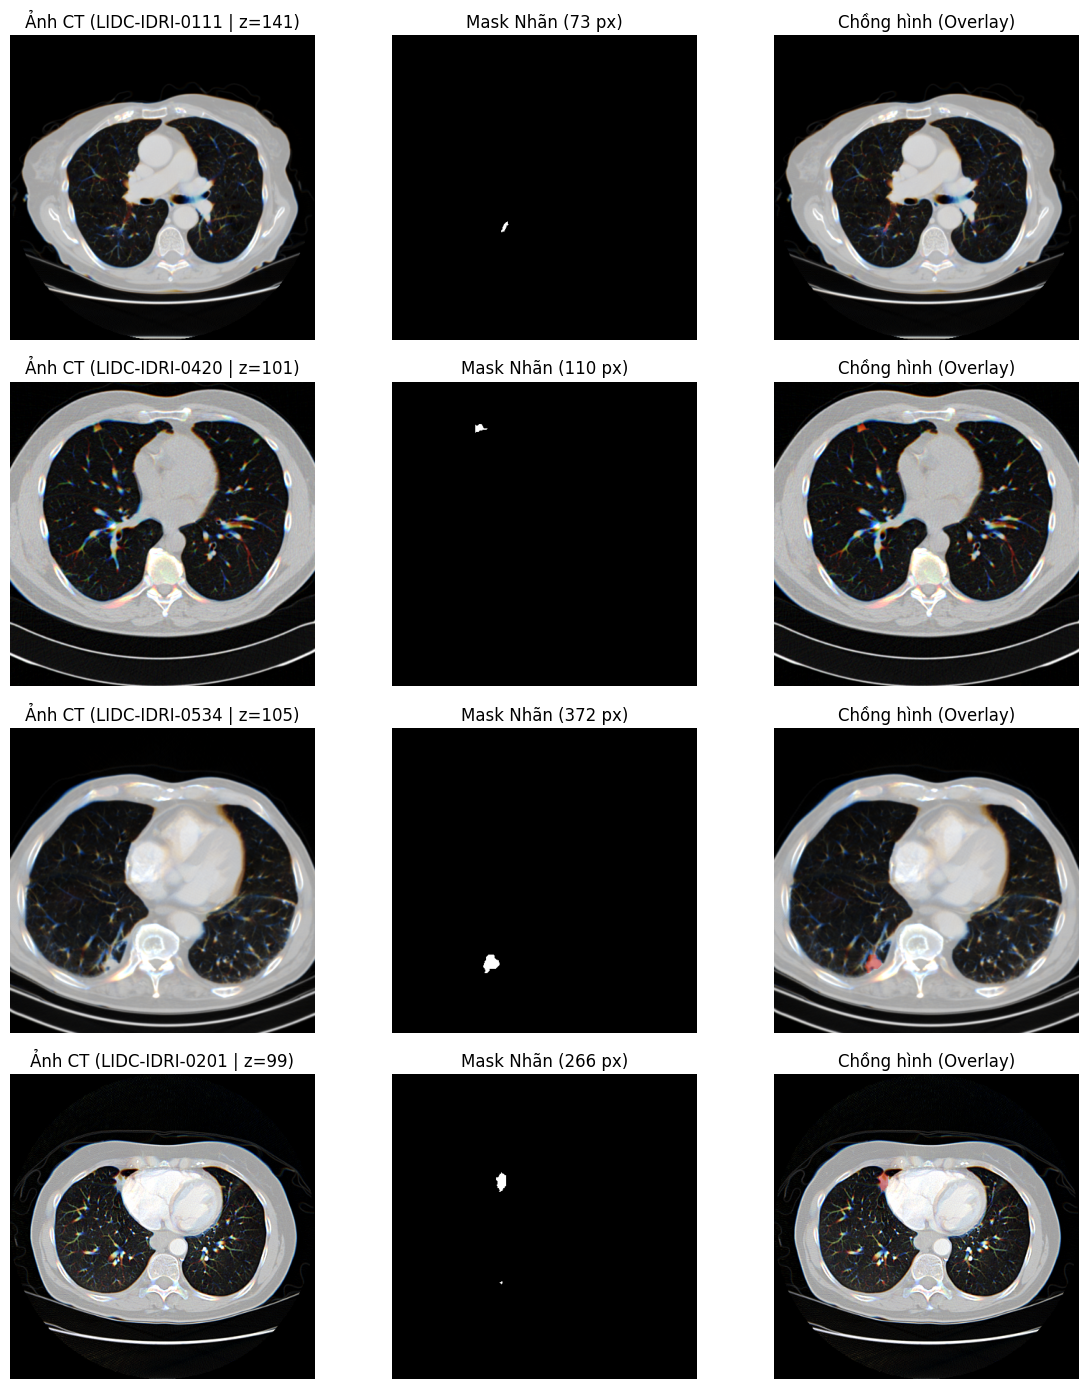

In [5]:
# Cell 5: Trực quan hóa ngẫu nhiên 4 mẫu đã trích xuất
import matplotlib.pyplot as plt
import random

if extracted_records:
    sample_list = random.sample(extracted_records, min(4, len(extracted_records)))
    fig, axes = plt.subplots(len(sample_list), 3, figsize=(12, 3.5 * len(sample_list)))
    if len(sample_list) == 1:
        axes = [axes]

    for i, item in enumerate(sample_list):
        img_p = OUTPUT_DIR / item["image_path"]
        msk_p = OUTPUT_DIR / item["mask_path"]

        if SAVE_FORMAT == "png":
            im = cv2.imread(str(img_p))
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
            mk = cv2.imread(str(msk_p), cv2.IMREAD_GRAYSCALE)
        else:
            im = np.load(str(img_p))
            mk = np.load(str(msk_p)) * 255

        # Tạo overlay màu đỏ
        overlay = im.copy()
        overlay[mk > 0] = [255, 0, 0]  # Đỏ cho vùng khối u
        blended = cv2.addWeighted(im, 0.65, overlay, 0.35, 0)

        axes[i][0].imshow(im)
        axes[i][0].set_title(f"Ảnh CT ({item['patient_id']} | z={item['z']})")
        axes[i][0].axis("off")

        axes[i][1].imshow(mk, cmap="gray")
        axes[i][1].set_title(f"Mask Nhãn ({item['positive_pixels']} px)")
        axes[i][1].axis("off")

        axes[i][2].imshow(blended)
        axes[i][2].set_title("Chồng hình (Overlay)")
        axes[i][2].axis("off")

    plt.tight_layout()
    plt.show()

## 🔗 HƯỚNG DẪN DÙNG NGAY VỚI MÔ HÌNH HUẤN LUYỆN (UNet Baseline)

Thư mục `segmented_slices` vừa tạo ra nằm ngay trong `SOURCES/data/` cùng cấp với `processed` và `raw`:
```text
SOURCES/data/segmented_slices/
├── train/{images, masks}  (9,343 mẫu)
├── val/{images, masks}    (1,699 mẫu)
└── test/{images, masks}   (2,006 mẫu)
```

Để huấn luyện trực tiếp mạng **U-Net Baseline** (`SOURCES/unet_baseline/`), bạn chỉ cần sửa 1 dòng duy nhất trong file cấu hình `SOURCES/unet_baseline/configs/config.yaml`:
```yaml
data:
  root_dir: "../data/segmented_slices"   # Trỏ sang thư mục vừa trích xuất
  image_size: 256
```
Sau đó bấm chạy file `train_on_colab.ipynb` của `unet_baseline` là mô hình sẽ được huấn luyện 100% trên toàn bộ các lát cắt có u mà không bị pha loãng bởi hàng trăm ngàn lát cắt rỗng!